# Measurements explorer

Load MIRICO Orion measurements from Azure blob storage (SAS-token access) for one or more deployments and work with them through a small `Deployment` object:

| attribute / method | what you get |
|---|---|
| `d.report` | every reading (one row per retro measurement) |
| `d.retros` | retro names |
| `d.retro('R4')` | readings for one retro, time-indexed, with CH$_4$ in ppm |
| `d.ch4(rate)` / `d.ch4(rate, stderr=True)` | wide table, one column per retro (ppm), optionally resampled |
| `d.sensors` | Orion / retro coordinates (LLA) and retro ENU offsets from the Orion (m) |
| `d.wind` | high-res wind if loaded, else the low-res wind from the report |
| `d.summary()` | per-retro counts, time span and CH$_4$ stats |
| `d.obs_targets(rate)` | binned targets in the `{'R4obs0': {'val', 'sigma'}}` form used by the history-matching notebook |
| `d.data` / `d.dataset` | the underlying pyelq `MiricoData` / raw `xarray.Dataset` |

Downloaded datasets are cached under `output/measurements_cache/`, so re-running is quick. Pass `refresh=True` to re-download.

## 1. Credentials
Pick the env file. `.env` holds the limited read-only `limitedmiricoblob` credentials (SAS tokens); `.env_old` is the full internal set.

Any `AZURE_STORAGE_*` / `MIRICO_*` variables already in the environment are cleared first, so what you test is exactly what is in `ENV_FILE` (nothing leaks in from a previously loaded `.env`).

In [ ]:
import json
import os
import pickle
import sys
from dataclasses import dataclass
from pathlib import Path
from urllib.error import HTTPError
from urllib.parse import parse_qs
from urllib.request import urlopen

import numpy as np
import pandas as pd
from dotenv import load_dotenv

ENV_FILE = Path('.env')   # or Path('.env_old') for the full internal set

# Allow running from the repo root as well as from mirico/
if not ENV_FILE.exists() and (Path('mirico') / ENV_FILE).exists():
    ENV_FILE = Path('mirico') / ENV_FILE
if not ENV_FILE.exists():
    raise FileNotFoundError(f'{ENV_FILE} not found (cwd = {Path.cwd()})')

# Make pyelq importable when it is a local checkout rather than an installed package
mipyelq_src = Path('/Users/hamid/mirico/mipyelq/src')
if mipyelq_src.exists() and str(mipyelq_src) not in sys.path:
    sys.path.insert(0, str(mipyelq_src))

for key in [k for k in os.environ if k.startswith(('AZURE_STORAGE_', 'MIRICO_'))]:
    del os.environ[key]
load_dotenv(ENV_FILE, override=True)
print('Loaded credentials from', ENV_FILE.resolve())

In [2]:
def sas_fields(token):
    '''Parse the non-secret fields of a SAS token (scope, permissions, expiry).'''
    return {k: v[0] for k, v in parse_qs(token).items() if k != 'sig'}


def describe_credentials():
    '''Table of the loaded variables. Token signatures are never shown.'''
    now = pd.Timestamp.now(tz='UTC')
    rows = []
    for key in sorted(k for k in os.environ if k.startswith(('AZURE_STORAGE_', 'MIRICO_'))):
        value = os.environ[key]
        row = {'variable': key}
        if 'SAS_TOKEN' in key:
            f = sas_fields(value)
            expires = pd.Timestamp(f['se']) if 'se' in f else pd.NaT
            row.update(scope={'c': 'container', 'b': 'blob'}.get(f.get('sr'), f.get('sr')),
                       permissions=f.get('sp'), expires=expires,
                       valid_now=bool(pd.notna(expires) and expires > now))
        else:
            row['value'] = value
        rows.append(row)
    return pd.DataFrame(rows).set_index('variable')


describe_credentials()

,value,scope,permissions,expires,valid_now
variable,,,,,
AZURE_STORAGE_ACCOUNT,limitedmiricoblob,NaN,NaN,NaT,NaN
AZURE_STORAGE_SAS_TOKEN_TADI,NaN,container,rl,2026-11-15 11:38:00+00:00,True
MIRICO_ACCOUNT_NAME,limitedmiricoblob,NaN,NaN,NaT,NaN
MIRICO_INSTRUMENT,NG5,NaN,NaN,NaT,NaN


### Data sources and access check
A *source* is a blob container (plus, optionally, the folder inside it that holds the zarr files). Its SAS token is read from `AZURE_STORAGE_SAS_TOKEN_<SOURCE>` in `ENV_FILE`, e.g. `AZURE_STORAGE_SAS_TOKEN_TADI` for the `tadi` container.

- `path` set: data are loaded straight from that folder, no index needed (this is the case for `limitedmiricoblob`, which has no index token).
- `path=None`: `pyblobtools` looks the deployment up in the instrument index (needs `AZURE_STORAGE_SAS_TOKEN_INDEX`, i.e. the full internal `.env`).

The check lists a few blobs with each token, straight against the Azure REST API. `OK` means the token works; `AuthenticationFailed` means it was not signed for that account/container or has expired (the Storage Explorer tokens for `limitedmiricoblob` last at most 7 days).

In [3]:
ACCOUNT = os.environ.get('AZURE_STORAGE_ACCOUNT')

# source name -> container / folder inside it. The token comes from AZURE_STORAGE_SAS_TOKEN_<name>.
SOURCES = {
    'TADI': dict(container='tadi', path='TADI 10062025'),
    # With the full internal .env (miricoblob + index), e.g.:
    # 'NG5': dict(container='ng5-nuc11tnhi7', path=None),
}


def _xml_tag(body, tag):
    return [part.split(f'</{tag}>')[0] for part in body.split(f'<{tag}>')[1:]]


def sas_token(source):
    return os.environ.get(f'AZURE_STORAGE_SAS_TOKEN_{source.upper()}')


def check_access(source, n=5):
    container = SOURCES[source]['container']
    token = sas_token(source)
    if not token:
        return f'{source}: MISSING  no AZURE_STORAGE_SAS_TOKEN_{source.upper()} in {ENV_FILE}'
    url = (f'https://{ACCOUNT}.blob.core.windows.net/{container}'
           f'?restype=container&comp=list&delimiter=/&maxresults={n}&{token}')
    try:
        with urlopen(url, timeout=30) as resp:
            body = resp.read().decode()
    except HTTPError as err:
        reason = (_xml_tag(err.read().decode(), 'Code') or [err.reason])[0]
        return f'{source}: FAILED  HTTP {err.code} {reason}  ({ACCOUNT}/{container})'
    return f'{source}: OK  {ACCOUNT}/{container} -> {_xml_tag(body, "Name")}'


for source in SOURCES:
    print(check_access(source))

TADI: OK  limitedmiricoblob/tadi -> ['TADI 10062025/', 'tadi_all_data.nc.zst']


### (Optional) What data are available?
Lists the measurement zarr files in a source folder with the time span of each (parsed from the file names), so you can pick deployment windows. `_high_res` wind files and `setup_sideload.zarr` are skipped.

In [4]:
import re
from urllib.parse import quote

_SPAN = re.compile(r'(\d{4}-\d{2}-\d{2}t\d{2}-\d{2}-\d{2})z-(\d{4}-\d{2}-\d{2}t\d{2}-\d{2}-\d{2})z')


def _parse_ts(s):
    return pd.Timestamp(s[:10] + ' ' + s[11:].replace('-', ':'))


def list_measurement_files(source):
    '''One row per l1b measurement zarr in SOURCES[source]['path'], with start / end times.'''
    src, token = SOURCES[source], sas_token(source)
    prefix = (src['path'].rstrip('/') + '/') if src.get('path') else ''
    names, marker = [], ''
    while True:
        url = (f'https://{ACCOUNT}.blob.core.windows.net/{src["container"]}?restype=container&comp=list'
               f'&delimiter=/&prefix={quote(prefix)}&marker={quote(marker)}&{token}')
        with urlopen(url, timeout=60) as resp:
            body = resp.read().decode()
        names += [_xml_tag(bp, 'Name')[0].rstrip('/').split('/')[-1] for bp in _xml_tag(body, 'BlobPrefix')]
        marker = (_xml_tag(body, 'NextMarker') or [''])[0]
        if not marker:
            break
    rows = []
    for name in names:
        m = _SPAN.match(name)
        if m and name.endswith('-l1b.zarr'):
            rows.append(dict(start=_parse_ts(m.group(1)), end=_parse_ts(m.group(2)), file=name))
    df = pd.DataFrame(rows).sort_values('start').reset_index(drop=True)
    df['minutes'] = ((df['end'] - df['start']).dt.total_seconds() / 60).round(1)
    return df[['start', 'end', 'minutes', 'file']]


files = list_measurement_files('TADI')
files

,start,end,minutes,file
0,2025-06-10 17:51:47,2025-06-10 18:20:02,28.2,2025-06-10t17-51-47z-2025-06-10t18-20-02z-inst...
1,2025-06-11 00:00:52,2025-06-11 00:40:08,39.3,2025-06-11t00-00-52z-2025-06-11t00-40-08z-inst...
2,2025-06-12 00:00:05,2025-06-12 00:20:05,20.0,2025-06-12t00-00-05z-2025-06-12t00-20-05z-inst...
3,2025-06-13 00:12:08,2025-06-13 00:40:06,28.0,2025-06-13t00-12-08z-2025-06-13t00-40-06z-inst...
4,2025-06-14 00:19:45,2025-06-14 03:39:59,200.2,2025-06-14t00-19-45z-2025-06-14t03-39-59z-inst...
5,2025-06-15 00:00:10,2025-06-15 00:20:00,19.8,2025-06-15t00-00-10z-2025-06-15t00-20-00z-inst...
6,2025-06-16 00:12:06,2025-06-16 00:40:01,27.9,2025-06-16t00-12-06z-2025-06-16t00-40-01z-inst...
7,2025-06-17 00:15:03,2025-06-17 00:39:56,24.9,2025-06-17t00-15-03z-2025-06-17t00-39-56z-inst...
8,2025-06-18 00:13:59,2025-06-18 00:40:06,26.1,2025-06-18t00-13-59z-2025-06-18t00-40-06z-inst...
9,2025-06-19 00:16:18,2025-06-19 00:40:04,23.8,2025-06-19t00-16-18z-2025-06-19t00-40-04z-inst...


## 2. Deployments
One entry per deployment / time window, all times UTC. `source` is a key of `SOURCES`; use the file list above to choose windows. The key is just a label you choose; use it to pick the deployment later. Add as many as you like.

In [5]:
DEPLOYMENTS = {
    'tadi_2025-06-10': dict(source='TADI', start='2025-06-10 17:50:00', end='2025-06-10 18:25:00'),
    # 'tadi_2025-06-11': dict(source='TADI', start='2025-06-11 00:00:00', end='2025-06-11 00:45:00'),
}

EXTRA_LOADERS = ['hf_wind', 'lf_wind', 'settings', 'environment']
CACHE_DIR = Path('output/measurements_cache')

In [6]:
import warnings
warnings.simplefilter('ignore', category=FutureWarning)

import pyblobtools as pbt
from pyelq.coordinate_system import LLA
from pyelq.data_access.xarray import load_from_xarray


def _decode(value):
    return value.decode('utf-8') if isinstance(value, bytes) else value


@dataclass
class Deployment:
    name: str
    source: str
    start: pd.Timestamp
    end: pd.Timestamp
    dataset: object   # raw xarray.Dataset from pyblobtools
    data: object      # pyelq MiricoData built from it

    @property
    def report(self):
        '''Every reading: one row per retro measurement (ch4 in mol/mol).'''
        return self.data.report

    @property
    def settings(self):
        return self.data.settings

    @property
    def retros(self):
        return sorted(self.report['retro_name'].unique())

    @property
    def sensors(self):
        '''Orion / retro positions per beam, plus retro ENU offsets (m) from the first Orion.'''
        rows = []
        for retro_id, s in self.settings.items():
            (o_lat, o_lon, o_alt), (r_lat, r_lon, r_alt) = s['orion_lla'], s['retro_lla']
            rows.append(dict(retro_name=_decode(s.get('retro_name', retro_id)), retro_id=retro_id,
                             orion_lat=o_lat, orion_lon=o_lon, orion_alt=o_alt,
                             retro_lat=r_lat, retro_lon=r_lon, retro_alt=r_alt))
        df = pd.DataFrame(rows).set_index('retro_name').sort_index()
        ref = df.iloc[0]
        enu = LLA(latitude=df['retro_lat'].to_numpy(), longitude=df['retro_lon'].to_numpy(),
                  altitude=df['retro_alt'].to_numpy()).to_enu(
            ref_latitude=ref['orion_lat'], ref_longitude=ref['orion_lon'], ref_altitude=ref['orion_alt'])
        df['east'], df['north'], df['up'] = enu.east, enu.north, enu.up
        return df

    @property
    def wind(self):
        '''High-res wind if it was loaded, otherwise the low-res wind columns of the report.'''
        hr = getattr(self.data, 'high_res_wind', None)
        if hr is not None and len(hr):
            tcol = 'windtime' if 'windtime' in hr.columns else 'timestamp'
            return hr.set_index(tcol).sort_index()
        cols = [c for c in ('windx', 'windy', 'windz') if c in self.report.columns]
        return self.report.set_index('timestamp')[cols].sort_index()

    def retro(self, name):
        '''Readings for one retro, indexed by time, with CH4 in ppm added.'''
        df = self.report[self.report['retro_name'] == name].set_index('timestamp').sort_index()
        return df.assign(ch4_ppm=df['ch4'] * 1e6, ch4_stderr_ppm=df['ch4_stderr'] * 1e6)

    def ch4(self, rate=None, stderr=False):
        '''Wide table, one column per retro (ppm). rate e.g. "60s" or "300s" resamples to bin means.
        Unresampled, the table is mostly NaN because the Orion visits retros in turn.'''
        col = 'ch4_stderr' if stderr else 'ch4'
        wide = self.report.pivot_table(index='timestamp', columns='retro_name', values=col) * 1e6
        return wide.resample(rate).mean() if rate else wide

    def obs_targets(self, rate='300s'):
        '''Binned targets keyed like the history-matching notebook: {"R4obs0": {"val": ppm, "sigma": ppm}}.'''
        mean, sd = self.ch4(rate), self.ch4(rate, stderr=True)
        targets = {}
        for retro in mean.columns:
            for i, (m, s) in enumerate(zip(mean[retro], sd[retro])):
                if pd.notna(m) and pd.notna(s):
                    targets[f'{retro}obs{i}'] = {'val': m, 'sigma': s}
        return targets

    def summary(self):
        g = self.report.groupby('retro_name')
        return pd.DataFrame({
            'n_readings': g.size(),
            'first': g['timestamp'].min(),
            'last': g['timestamp'].max(),
            'ch4_mean_ppm': g['ch4'].mean() * 1e6,
            'ch4_max_ppm': g['ch4'].max() * 1e6,
            'stderr_mean_ppm': g['ch4_stderr'].mean() * 1e6,
        })

    def __repr__(self):
        return (f'<Deployment {self.name}: {self.source} {self.start} -> {self.end}, '
                f'{len(self.report)} readings, retros={self.retros}>')


def _load_from_blob(cfg):
    '''Read the zarr files covering cfg's time window with the source's SAS token.'''
    source = cfg['source']
    src, token = SOURCES[source], sas_token(source)
    if not token:
        raise ValueError(f'no AZURE_STORAGE_SAS_TOKEN_{source.upper()} in {ENV_FILE}')
    auth = pbt.SASTokenAuthentication(account_name=ACCOUNT, sas_token=token)
    start, end = pd.Timestamp(cfg['start']).to_pydatetime(), pd.Timestamp(cfg['end']).to_pydatetime()
    kwargs = dict(auth=auth, extra_loaders=cfg.get('extra_loaders', EXTRA_LOADERS))
    if src.get('path'):
        kwargs.update(override_path=f"{src['container']}/{src['path']}", search_index=False)
        if not os.environ.get('AZURE_STORAGE_SAS_TOKEN_INDEX'):
            # pyblobtools queries the index even when override_path is given, and fails without an
            # index token. Skip that lookup: the path is already known.
            sys.modules['pyblobtools.load_zarr']._get_paths_from_index = lambda *a, **k: None
    return pbt.load_zarr(source, start, end, **kwargs)


def load_deployment(name, refresh=False):
    '''Load a deployment from DEPLOYMENTS, using the local cache unless refresh=True.'''
    cfg = DEPLOYMENTS[name]
    cache = CACHE_DIR / f'{name}.pkl'
    if cache.exists() and not refresh:
        with open(cache, 'rb') as fh:
            dataset = pickle.load(fh)
    else:
        dataset = _load_from_blob(cfg).load()
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        with open(cache, 'wb') as fh:
            pickle.dump(dataset, fh)
    data = load_from_xarray(dataset, post_calculate_diffusion_params=True)
    data.report['retro_name'] = data.report['retro_name'].apply(_decode)
    data.report['timestamp'] = pd.to_datetime(data.report['timestamp'])
    return Deployment(name, cfg['source'], pd.Timestamp(cfg['start']), pd.Timestamp(cfg['end']),
                      dataset, data)

## 3. Load
Loads every entry in `DEPLOYMENTS`. A failure for one deployment is reported and the rest carry on.

In [7]:
deployments = {}
for name in DEPLOYMENTS:
    try:
        deployments[name] = load_deployment(name)
        print(deployments[name])
    except Exception as err:
        print(f'{name}: FAILED to load -> {type(err).__name__}: {err}')

<Deployment tadi_2025-06-10: TADI 2025-06-10 17:50:00 -> 2025-06-10 18:25:00, 145 readings, retros=['R10', 'R11', 'R12', 'R13', 'R14', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9']>


/workspaces/hmepy/.venv/lib/python3.13/site-packages/pyelq/support_functions/diffusion_parameters.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  mean_wind_dir = circmean(window["wind_dir"], high=2 * np.pi, low=0)


## 4. Working with one deployment

In [8]:
d = deployments['tadi_2025-06-10']
d.summary()

,n_readings,first,last,ch4_mean_ppm,ch4_max_ppm,stderr_mean_ppm
retro_name,,,,,,
R10,11,2025-06-10 17:53:32.115000064,2025-06-10 18:23:25.990000128,1.871376,1.912122,0.009760
R11,11,2025-06-10 17:53:46.420000000,2025-06-10 18:23:39.185999872,1.862214,1.884377,0.009901
R12,11,2025-06-10 17:53:59.223000064,2025-06-10 18:23:53.296999936,1.887197,1.902305,0.008536
R13,11,2025-06-10 17:54:12.036000000,2025-06-10 18:24:07.784999936,1.888049,1.911339,0.008977
R14,11,2025-06-10 17:54:25.216000000,2025-06-10 18:24:21.500000000,1.894080,1.922360,0.008811
R2,12,2025-06-10 17:51:47.376999936,2025-06-10 18:24:42.588000000,1.856882,1.889688,0.010145
R3,12,2025-06-10 17:52:01.363000064,2025-06-10 18:24:56.820999936,1.926860,1.948504,0.009841
R4,11,2025-06-10 17:52:14.336000000,2025-06-10 18:22:01.945999872,1.853156,1.890260,0.010040
R5,11,2025-06-10 17:52:27.344999936,2025-06-10 18:22:16.239000064,1.920148,1.958803,0.009097


In [9]:
d.sensors

,retro_id,orion_lat,orion_lon,orion_alt,retro_lat,retro_lon,retro_alt,east,north,up
retro_name,,,,,,,,,,
R1,retro_R1,43.412338,-0.642253,91.54,43.412641,-0.643060,91.562,-65.378640,33.642116,0.021577
R10,retro_R10,43.412338,-0.642253,91.54,43.412865,-0.642501,97.132,-20.127040,58.528814,5.591699
R11,retro_R11,43.412338,-0.642253,91.54,43.413349,-0.642610,92.037,-28.930847,112.280138,0.495944
R12,retro_R12,43.412338,-0.642253,91.54,43.413001,-0.642382,93.858,-10.480611,73.638691,2.317565
R13,retro_R13,43.412338,-0.642253,91.54,43.413221,-0.642279,92.370,-2.130131,98.025643,0.829245
R14,retro_R14,43.412338,-0.642253,91.54,43.413089,-0.641960,92.263,23.666378,83.382386,0.722410
R2,retro_R2,43.412338,-0.642253,91.54,43.413002,-0.643602,96.621,-109.325611,73.806254,5.079637
R3,retro_R3,43.412338,-0.642253,91.54,43.412667,-0.642805,92.724,-44.741268,36.563947,1.183738
R4,retro_R4,43.412338,-0.642253,91.54,43.413226,-0.643432,96.499,-95.548189,98.648556,4.957521


In [10]:
d.retro(d.retros[0]).head()

,measurement_validity,ch4,ch4_stderr,diagnostics_settings_id,temperature_k,pressure_torr,retro_id,windx,windy,windz,retro_name,pyelq_retro_id,turb_hor,turb_vert,ch4_ppm,ch4_stderr_ppm
timestamp,,,,,,,,,,,,,,,,
2025-06-10 17:53:32.115000064,10,0.000002,8.987155e-09,976,305.2750,751.096768,640,-0.657200,-1.877800,-0.015200,R10,retro_R10,0.187267,0.203246,1.865467,0.008987
2025-06-10 17:56:30.526000128,10,0.000002,9.826766e-09,976,305.3375,751.216778,640,-0.961765,-2.414314,-0.002353,R10,retro_R10,0.225534,0.156476,1.851199,0.009827
2025-06-10 17:59:23.607000064,10,0.000002,9.857046e-09,976,305.5875,751.179275,640,0.060000,-2.107400,0.146600,R10,retro_R10,0.283778,0.153422,1.873547,0.009857
2025-06-10 18:02:21.804000000,10,0.000002,9.561228e-09,976,305.6500,751.119270,640,-1.025918,-1.841429,0.001020,R10,retro_R10,0.289766,0.139756,1.892445,0.009561
2025-06-10 18:05:16.873999872,10,0.000002,8.967341e-09,976,305.6500,751.126770,640,-0.794902,-2.160588,0.029020,R10,retro_R10,0.178379,0.140897,1.912122,0.008967


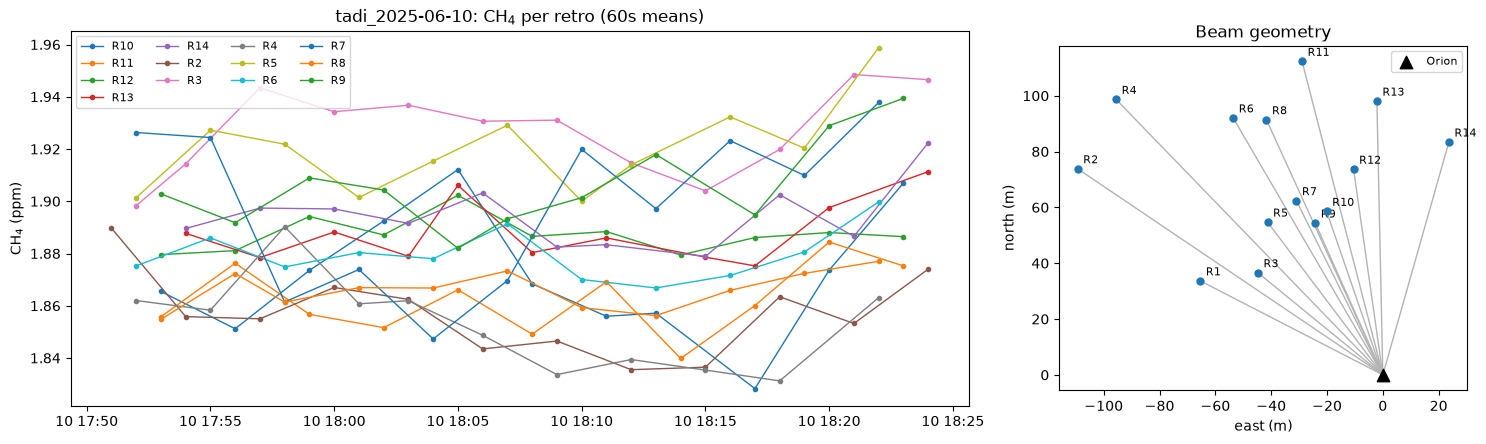

In [11]:
import matplotlib.pyplot as plt

rate = '60s'
mean = d.ch4(rate)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})

ax = axes[0]
for retro in mean.columns:
    series = mean[retro].dropna()
    ax.plot(series.index, series.values, marker='.', lw=1, label=retro)
ax.set_ylabel('CH$_4$ (ppm)')
ax.set_title(f'{d.name}: CH$_4$ per retro ({rate} means)')
ax.legend(ncol=4, fontsize=8)

ax = axes[1]
s = d.sensors
for retro, row in s.iterrows():
    ax.plot([0, row['east']], [0, row['north']], color='0.7', lw=1)
    ax.annotate(retro, (row['east'], row['north']), textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.scatter(s['east'], s['north'], s=25, zorder=3)
ax.scatter([0], [0], marker='^', s=80, color='k', zorder=3, label='Orion')
ax.set_aspect('equal')
ax.set_xlabel('east (m)')
ax.set_ylabel('north (m)')
ax.set_title('Beam geometry')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [12]:
d.wind.describe()

,windx,windy,windz
count,19934.000000,19934.000000,19934.000000
mean,-0.295476,-1.910600,0.056925
std,0.469993,0.491087,0.191711
min,-2.100000,-3.890000,-0.790000
25%,-0.590000,-2.260000,-0.060000
50%,-0.280000,-1.900000,0.060000
75%,0.010000,-1.540000,0.180000
max,1.790000,-0.530000,1.280000


## 5. Across deployments

In [13]:
pd.concat({name: dep.summary() for name, dep in deployments.items()}, names=['deployment'])

n_readings                         first  \
deployment      retro_name                                             
tadi_2025-06-10 R10                 11 2025-06-10 17:53:32.115000064   
                R11                 11 2025-06-10 17:53:46.420000000   
                R12                 11 2025-06-10 17:53:59.223000064   
                R13                 11 2025-06-10 17:54:12.036000000   
                R14                 11 2025-06-10 17:54:25.216000000   
                R2                  12 2025-06-10 17:51:47.376999936   
                R3                  12 2025-06-10 17:52:01.363000064   
                R4                  11 2025-06-10 17:52:14.336000000   
                R5                  11 2025-06-10 17:52:27.344999936   
                R6                  11 2025-06-10 17:52:40.246000128   
                R7                  11 2025-06-10 17:52:52.849999872   
                R8                  11 2025-06-10 17:53:05.624999936   
                R9                  11 2025-06-10 17:53:18.327000064   

                                                    last  ch4_mean_ppm  \
deployment      retro_name                                               
tadi_2025-06-10 R10        2025-06-10 18:23:25.990000128      1.871376   
                R11        2025-06-10 18:23:39.185999872      1.862214   
                R12        2025-06-10 18:23:53.296999936      1.887197   
                R13        2025-06-10 18:24:07.784999936      1.888049   
                R14        2025-06-10 18:24:21.500000000      1.894080   
                R2         2025-06-10 18:24:42.588000000      1.856882   
                R3         2025-06-10 18:24:56.820999936      1.926860   
                R4         2025-06-10 18:22:01.945999872      1.853156   
                R5         2025-06-10 18:22:16.239000064      1.920148   
                R6         2025-06-10 18:22:30.368000000      1.879514   
                R7         2025-06-10 18:22:44.113999872      1.899167   
                R8         2025-06-10 18:22:58.404000000      1.866039   
                R9         2025-06-10 18:23:12.268000000      1.905949   

                            ch4_max_ppm  stderr_mean_ppm  
deployment      retro_name                                
tadi_2025-06-10 R10            1.912122         0.009760  
                R11            1.884377         0.009901  
                R12            1.902305         0.008536  
                R13            1.911339         0.008977  
                R14            1.922360         0.008811  
                R2             1.889688         0.010145  
                R3             1.948504         0.009841  
                R4             1.890260         0.010040  
                R5             1.958803         0.009097  
                R6             1.899748         0.009520  
                R7             1.937821         0.008966  
                R8             1.876997         0.008961  
                R9             1.939387         0.009092

## 6. Handing data to the history-matching notebook
`d.data` is the same `MiricoData` object the history-matching notebook calls `liv_data`, and `d.obs_targets('300s')` reproduces its `obs_targets`. For example:

```python
liv_data = d.data
obs_targets = d.obs_targets('300s')
```

In [14]:
obs_targets = d.obs_targets('300s')
print(len(obs_targets), 'targets, e.g.', next(iter(obs_targets.items())))

91 targets, e.g. ('R10obs0', {'val': 1.86546696661409, 'sigma': 0.00898715507135249})
